In [1]:
import copy

import config as cfg
from data_acquirer import get_data, gen_data
from data_processor import process
from solver import solve_pdpcr,mass_solve, SolvedInstance
import visualization
from operator import itemgetter
import matplotlib.pyplot as plt

import numpy as np
import pandas as pd
import time

In [5]:
"""
SOLVE_METHOD ={
1: solve_vrp_sumofcosts,
2: solve_flow_makespan,
3: solve_vrp_makespan,
4: solve_vrp_ver2
}
"""

method = 2
random_data = False
total_robots = 5
total_tasks = 50
data_name = 'data2'

In [6]:

is_depot_task = False
if random_data:
    raw = gen_data(total_robots, total_tasks, False, is_depot_task)
else:
    raw = get_data(data_name,'csv', is_depot_task)

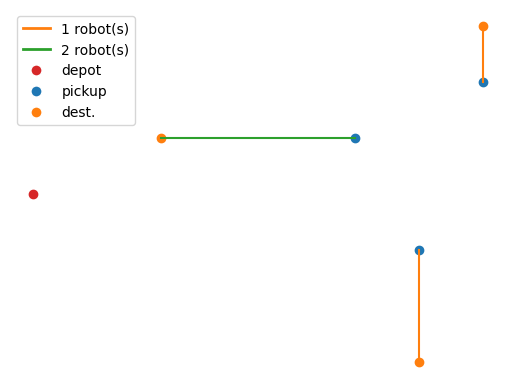

In [14]:
#TODO delete this cell
from matplotlib.lines import Line2D
def plot_map2(raw):
    depot, tasks = raw.unpack()
    fig, ax = plt.subplots()
    ax.axis('off')
    plt.scatter(depot.coor[0], depot.coor[1],c= 'C3', label = 'depot')
    for task in tasks:
        pickup_coor = task.pickup_coor
        dest_coor = task.dest_coor
        plt.scatter(pickup_coor[0], pickup_coor[1],c = 'C0',)
        plt.scatter(dest_coor[0], dest_coor[1], c ='C1',)
        xs = [pickup_coor[0],dest_coor[0]]
        ys = [pickup_coor[1],dest_coor[1]]
        plt.plot(xs, ys, c = cfg.PATH_COLOR[task.n])
        
    robots_required = set([task.n for task in tasks])
    legends_path ={f"{i} robot(s)":Line2D([0],[0], color = f"C{i}",lw = 2) for i in robots_required}
    legends_node = {
        "depot" : Line2D([0], [0], marker='o', color='w',markerfacecolor='C3', markersize= 8),
        "pickup" : Line2D([0], [0], marker='o', color='w',markerfacecolor='C0', markersize= 8),
        "dest." : Line2D([0], [0], marker='o', color='w',markerfacecolor='C1', markersize= 8),
    }
    legends = dict(legends_path,**legends_node)
    plt.legend(legends.values(), legends.keys())
    plt.plot()
        
plot_map2(raw)
plt.savefig(f"img/{data_name}result2.png", format="PNG")

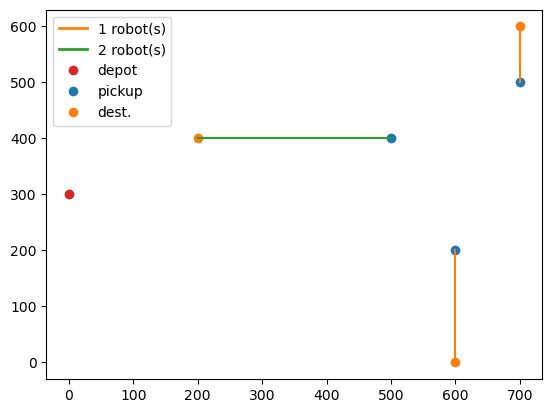

In [11]:
try:
    raw.depot.coor = raw.depot.pickup_coor
except Exception as e:
    pass
visualization.plot_map(raw)

In [ ]:
processed_data = process(raw, method) 
solve_result = solve_pdpcr(processed_data, total_robots, method)

In [ ]:
solve_result['sol']

In [ ]:
sol = solve_result['sol']
x = solve_result['x']
f = solve_result['f']

In [ ]:
sol.get_value_df(f)

### Quick visualization

In [ ]:
df_x = sol.get_value_df(x,key_column_names=['from','to'])
df_x_moved = df_x[df_x['value']!=0]
np_moved = df_x_moved.to_numpy()
task_idx_mapper = {task.index: task for task in processed_data.tasks}
task_idx_mapper[0] =processed_data.depot

In [ ]:
solve_result['z']

In [ ]:
processed_data.tasks

In [ ]:
processed_data.depot

In [ ]:
depot = raw.depot
plt.scatter(depot.coor[0], depot.coor[1],c= 'C3', label = 'depot')
for moved_edge in np_moved:
    from_task_idx = int(moved_edge[0])
    to_task_idx = int(moved_edge[1])
    if from_task_idx ==0:
        frm_task_dest = task_idx_mapper[from_task_idx].coor
    else:
        frm_task_dest = task_idx_mapper[from_task_idx].dest_coor
    if to_task_idx ==0:
        to_task_pickup = task_idx_mapper[to_task_idx].coor
    else:
        to_task_pickup = task_idx_mapper[to_task_idx].t
    xs = [frm_task_dest[0],to_task_pickup[0]]
    ys = [frm_task_dest[1],to_task_pickup[1]]
    plt.plot(xs, ys)
for task in raw.tasks:
        pickup_coor = task.pickup_coor
        dest_coor = task.dest_coor
        plt.scatter(pickup_coor[0], pickup_coor[1],c = 'C0',)
        plt.scatter(dest_coor[0], dest_coor[1], c ='C1',)
        xs = [pickup_coor[0],dest_coor[0]]
        ys = [pickup_coor[1],dest_coor[1]]
        plt.plot(xs, ys, c = cfg.PATH_COLOR[task.n])

In [ ]:
processed_data.tasks

In [ ]:
MOVED_EDGE_GETTER ={
    1:visualization.get_moved_edges,
    2:visualization.get_moved_edges_flow
}

In [ ]:
task_idx_mapper = {task.index: task for task in processed_data.tasks}

In [ ]:
node_idx_mapper = {node.index: node for node in processed_data.tasks}
moved_edges = MOVED_EDGE_GETTER[method](solve_result)
paths = visualization.get_paths(moved_edges,total_robots)
tasks_path = visualization.get_tasks_path(paths, processed_data.nodes)
paths_coor = visualization.get_paths_coor(paths,node_idx_mapper)
edge_paths = visualization.get_edge_paths(paths)
if method ==2:
    node_idx_mapper = {node.index: node for node in processed_data.nodes[:-1]}

## Visualization

In [ ]:
import networkx as nx

In [ ]:
G = nx.DiGraph()
V =[node for node in node_idx_mapper.keys()]
E = moved_edges
pos = {idx: node.coor for idx,node in node_idx_mapper.items()}
        
G.add_nodes_from(V)        
G.add_edges_from(E)

color_map = []
for node in V:
    if node ==0:
        color_map.append('red')
    elif node_idx_mapper[node].node_type ==1:
        color_map.append('C0')
    elif node_idx_mapper[node].node_type ==2:
        color_map.append('C1')

In [ ]:
edges_color = []
edges_style = []
for edge in E:
    for i in range(len(edge_paths)):
        if edge in edge_paths[i]:
            edges_color.append(f'C{i}')
            edges_style.append((1,(3+i*2,5)))

In [ ]:
nx.draw(G,pos = pos, node_color = color_map,node_size =50, edge_color = edges_color, style = edges_style, arrowsize =15)
if random_data == False:
    plt.savefig(f"img/{data_name}result.png", format="PNG")
else:
    plt.savefig(f"img/{seed_num}_{current_time}result_random.png", format="PNG")
plt.show()

## Mass Solve

In [ ]:
Rs = [2,3,4]
Ts = [5,10,15]

Rs = [1,2] 
Ts = [5]
total_instances = 5
cfg.LOG_OUTPUT = False
full_solved_instances = []
for T in Ts:
    for R in Rs:
        print(f'__________________________solving for {T} tasks and {R} robot__________________________')
        solved_instances = mass_solve(T,R,2,total_instances = total_instances,log_output = False)
        [full_solved_instances.append(solved_instance) for solved_instance in solved_instances]

## Mass Solve Remastered

In [2]:
Rs = [3,4]
Ts = [5,10,15]
instance_each_case = 4
i = 0
is_depot_task = False
instances = [gen_data(R, T, False, is_depot_task) for R in Rs for T in Ts for _ in range(instance_each_case)]

In [ ]:
def instance_to_df(raw):
    depot = raw.depot
    t_index = [depot.task_idx]
    x_p = [depot.coor[0]]
    y_p = [depot.coor[1]]
    x_d = [depot.coor[0]]
    y_d = [depot.coor[1]]
    n = [0]
    process_time = [0]
    
    tasks = raw.tasks
    
    for task in tasks:
        t_index.append(task.index)
        x_p.append(task.pickup_coor[0])
        y_p.append(task.pickup_coor[1])
        x_d.append(task.dest_coor[0])
        y_d.append(task.dest_coor[1])
        n.append(task.n)
        process_time.append(task.process_time)
    
    instance_inter = {}
    instance_inter['index'] = t_index
    instance_inter['x_pickup'] = x_p
    instance_inter['y_pickup'] = y_p
    instance_inter['x_dest'] = x_d
    instance_inter['y_dest'] = y_d
    instance_inter['robots_required'] = n
    instance_inter['process_time'] = process_time 
    df_instance = pd.DataFrame(instance_inter).round(2)
    
    return df_instance

In [ ]:
i = 0
for instance in instances:
    df_instance = instance_to_df(instance)
    df_instance.to_csv(f"./data/generated{i}.csv", index = False)
    i = i+1

In [6]:
method = 5
is_depot_task = False

solve_results = {}
data_names =[f"generated{i}" for i in range(24)]

for data_name in data_names:    
    raw = get_data(data_name,'csv', is_depot_task)
    total_robots = 4
    print(f'__________Solving for data {data_name} {total_robots} robots and {len(raw.tasks)} tasks__________')
    processed_data = process(raw, method) 
    solve_result = solve_pdpcr(processed_data, total_robots, method)
    solve_results[data_name] = solve_result

__________Solving for data generated0 4 robots and 5 tasks__________
C:\Users\CTNGUY~1\AppData\Local\Temp\VRP_ver_2_makespan.lp
Start solving vrp-based model for makespan obj.function using CPLEX
Version identifier: 22.1.0.0 | 2022-03-09 | 1a383f8ce
CPXPARAM_Read_DataCheck                          1
CPXPARAM_TimeLimit                               7200
CPXPARAM_MIP_Tolerances_MIPGap                   0
Tried aggregator 2 times.
MIP Presolve eliminated 13 rows and 13 columns.
MIP Presolve modified 20 coefficients.
Aggregator did 1 substitutions.
Reduced MIP has 42 rows, 36 columns, and 145 nonzeros.
Reduced MIP has 30 binaries, 0 generals, 0 SOSs, and 0 indicators.
Presolve time = 0.16 sec. (0.17 ticks)
Found incumbent of value 1360.000000 after 0.42 sec. (0.23 ticks)
Probing fixed 0 vars, tightened 2 bounds.
Probing time = 0.03 sec. (0.12 ticks)
Cover probing fixed 0 vars, tightened 11 bounds.
Tried aggregator 2 times.
Detecting symmetries...
MIP Presolve eliminated 2 rows and 0 column

Reduced MIP has 23 binaries, 0 generals, 0 SOSs, and 0 indicators.
Presolve time = 0.23 sec. (0.11 ticks)
Probing fixed 11 vars, tightened 3 bounds.
Probing time = 0.02 sec. (0.04 ticks)
Cover probing fixed 0 vars, tightened 13 bounds.
Tried aggregator 2 times.
MIP Presolve eliminated 14 rows and 13 columns.
MIP Presolve modified 31 coefficients.
Aggregator did 3 substitutions.
Reduced MIP has 13 rows, 13 columns, and 48 nonzeros.
Reduced MIP has 8 binaries, 0 generals, 0 SOSs, and 0 indicators.
Presolve time = 0.20 sec. (0.09 ticks)
Probing time = 0.00 sec. (0.01 ticks)
Tried aggregator 1 time.
Detecting symmetries...
Reduced MIP has 13 rows, 13 columns, and 48 nonzeros.
Reduced MIP has 8 binaries, 0 generals, 0 SOSs, and 0 indicators.
Presolve time = 0.09 sec. (0.03 ticks)
Probing time = 0.00 sec. (0.01 ticks)
Clique table members: 1.
MIP emphasis: balance optimality and feasibility.
MIP search method: dynamic search.
Parallel mode: deterministic, using up to 6 threads.

Root node pr

__________Solving for data generated6 4 robots and 10 tasks__________
C:\Users\CTNGUY~1\AppData\Local\Temp\VRP_ver_2_makespan.lp
Start solving vrp-based model for makespan obj.function using CPLEX
Version identifier: 22.1.0.0 | 2022-03-09 | 1a383f8ce
CPXPARAM_Read_DataCheck                          1
CPXPARAM_TimeLimit                               7200
CPXPARAM_MIP_Tolerances_MIPGap                   0
Tried aggregator 2 times.
MIP Presolve eliminated 23 rows and 23 columns.
MIP Presolve modified 40 coefficients.
Aggregator did 1 substitutions.
Reduced MIP has 132 rows, 121 columns, and 540 nonzeros.
Reduced MIP has 110 binaries, 0 generals, 0 SOSs, and 0 indicators.
Presolve time = 0.25 sec. (0.60 ticks)
Found incumbent of value 2046.000000 after 0.44 sec. (0.82 ticks)
Probing time = 0.00 sec. (0.21 ticks)
Cover probing fixed 0 vars, tightened 22 bounds.
Tried aggregator 1 time.
Detecting symmetries...
MIP Presolve eliminated 6 rows and 0 columns.
MIP Presolve modified 188 coefficien

*   741+   95                         1454.5634      921.3010            36.66%
*  1233+  365                         1330.8944      921.3010            30.78%
*  7046   213      integral     0     1302.1462     1196.8833    63851    8.08%

Implied bound cuts applied:  204
Mixed integer rounding cuts applied:  3

Root node processing (before b&c):
  Real time             =    3.52 sec. (10.60 ticks)
Parallel b&c, 6 threads:
  Real time             =   10.75 sec. (202.63 ticks)
  Sync time (average)   =    4.26 sec.
  Wait time (average)   =    0.00 sec.
                          ------------
Total (root+branch&cut) =   14.27 sec. (213.22 ticks)
__________Solving for data generated8 4 robots and 15 tasks__________
C:\Users\CTNGUY~1\AppData\Local\Temp\VRP_ver_2_makespan.lp
Start solving vrp-based model for makespan obj.function using CPLEX
Version identifier: 22.1.0.0 | 2022-03-09 | 1a383f8ce
CPXPARAM_Read_DataCheck                          1
CPXPARAM_TimeLimit                           

 199686 112751        cutoff           1856.4849     1079.2284  4149414   41.87%
 204843 115023     1079.2284    24     1856.4849     1079.2284  4318652   41.87%
 209208 116919        cutoff           1856.4849     1079.2284  4436742   41.87%
 214413 120222     1378.4553    26     1856.4849     1079.2284  4610591   41.87%
 219800 123131        cutoff           1856.4849     1079.2284  4770818   41.87%
 224780 126294    infeasible           1856.4849     1079.2284  4916150   41.87%
 229239 128664        cutoff           1856.4849     1079.2284  5052702   41.87%
Elapsed time = 601.97 sec. (31908.14 ticks, tree = 45.37 MB, solutions = 24)
 234197 130556     1079.2284    25     1856.4849     1079.2284  5239868   41.87%
 239286 132644     1389.0736    27     1856.4849     1079.2284  5416760   41.87%
 244490 134706        cutoff           1856.4849     1079.2284  5562668   41.87%
 249573 136946     1820.4970    21     1856.4849     1079.2284  5770210   41.87%
 254836 139551     1079.2284    

 1193436 457605     1289.4977    17     1856.4849     1289.4977 33433794   30.54%
 1217189 465213     1289.4977    26     1856.4849     1289.4977 34116449   30.54%
 1241173 472232        cutoff           1856.4849     1289.4977 34719583   30.54%
 1265652 482164     1597.6731    15     1856.4849     1289.4977 35464065   30.54%
Elapsed time = 1538.20 sec. (206444.36 ticks, tree = 290.38 MB, solutions = 24)
 1290139 490987     1809.0321    14     1856.4849     1289.4977 36120844   30.54%
 1314968 498616    infeasible           1856.4849     1289.4977 36659679   30.54%
 1337970 508245     1289.4977    21     1856.4849     1289.4977 37314461   30.54%
 1363148 516795     1817.9421    10     1856.4849     1289.4977 37933532   30.54%
 1388007 524868     1668.8636    23     1856.4849     1289.4977 38509024   30.54%
 1411208 534042     1735.6120    14     1856.4849     1289.4977 39269330   30.54%
 1435366 538415     1491.6147    14     1856.4849     1295.5847 39768538   30.21%
 1457458 544199   

... (49 outputs left out)

*1024300+955118                         2858.2567      829.5106            70.98%
 1027551 955496      833.9951    79     2858.2567      829.5222 27464473   70.98%
 1034316 961877     1265.1124    44     2858.2567      829.5387 27634608   70.98%
*1037199+963041                         2824.3774      829.5535            70.63%
 1040418 963715     1340.1261    46     2824.3774      829.5587 27749072   70.63%
 1046371 970347     1196.0838    49     2824.3774      829.5923 27982825   70.63%
Elapsed time = 1508.88 sec. (475466.96 ticks, tree = 7268.76 MB, solutions = 29)
Nodefile size = 5216.94 MB (4430.40 MB after compression)
 1052659 975499     1340.4980   104     2824.3774      829.6012 28106585   70.63%
 1058205 981018     2568.7274    18     2824.3774      829.6362 28325542   70.63%
 1064751 987057     1910.2463    30     2824.3774      829.6499 28518473   70.63%
 1071400 993993     2046.7208    23     2824.3774      829.6622 28677206   70.62%
 1076703 999005     1584.1524    42     2

  62811     0      900.5345    51     2591.4299      Cuts: 43   727531   65.25%
  62811     0      900.5345    54     2591.4299      Cuts: 64   727700   65.25%
  62811     0      900.5345    46     2591.4299      Cuts: 38   727830   65.25%
  62811     0      900.5345    48     2591.4299      Cuts: 79   728008   65.25%
  62811     0      900.5345    39     2591.4299      Cuts: 10   728048   65.25%
  62811     0      900.5345    48     2591.4299      Cuts: 60   728146   65.25%
  62811     0      900.5345    33     2591.4299       Cuts: 8   728181   65.25%
  62811     0      900.5345    56     2591.4299      Cuts: 77   728313   65.25%
  62811     0      900.5345    47     2591.4299      Cuts: 15   728386   65.25%
  62811     0      900.5345    56     2591.4299      Cuts: 75   728514   65.25%
  62811     0      900.5345    48     2591.4299       Cuts: 9   728610   65.25%
  62811     2      900.5345    42     2591.4299      900.5345   728610   65.25%
* 62839+    3                         25

Elapsed time = 388.38 sec. (80555.23 ticks, tree = 283.60 MB, solutions = 30)
 323138 231970     1184.1727    37     2463.9553      900.5345  7854694   63.45%
 326159 234362     2243.0649    24     2463.9553      900.5345  7934028   63.45%
 329618 236759     1429.1199    26     2463.9553      900.5345  8011494   63.45%
 332456 240176     2114.5563    28     2463.9553      900.5345  8070314   63.45%
 336429 243598     1400.7177    40     2463.9553      900.5345  8124978   63.45%
 339957 246907     1294.2185    36     2463.9553      900.5345  8190646   63.45%
 343381 250811      943.6341    58     2463.9553      900.5345  8267789   63.45%
 347079 253419     1449.0402    26     2463.9553      900.5345  8321424   63.45%
 351112 258008     1294.1436    39     2463.9553      900.5345  8398052   63.45%
 363639 269086     1133.0110    46     2463.9553      900.5345  8608609   63.45%
Elapsed time = 428.02 sec. (92955.43 ticks, tree = 484.11 MB, solutions = 30)
 377342 280752     1391.4687    42

 1322207 1134380     1434.9152    34     2399.4053      900.5345 25013766   62.47%
 1333887 1146717      900.9474   109     2399.4053      900.5345 25260694   62.47%
 1345258 1157860     1919.0071    27     2399.4053      900.5345 25481849   62.47%
 1356013 1166748      903.9376    53     2399.4053      900.5345 25653155   62.47%
Elapsed time = 1237.33 sec. (398157.94 ticks, tree = 7202.94 MB, solutions = 32)
Nodefile size = 5145.82 MB (2946.20 MB after compression)
 1367967 1177811      900.5345    40     2399.4053      900.5345 25871916   62.47%
 1379834 1186050     1498.8155    33     2399.4053      900.5345 26019258   62.47%
 1391309 1197766     1705.1906    31     2399.4053      900.5345 26228722   62.47%
 1402202 1206997     1409.1281    39     2399.4053      900.5345 26395912   62.47%
 1413963 1219163      901.1774    73     2399.4053      900.5345 26628570   62.47%
 1426045 1230500     1455.5598    35     2399.4053      900.5345 26846314   62.47%
 1436514 1240460     1130.3045 

In [29]:
solve_results['generated21']

{'sol': docplex.mp.solution.SolveSolution(obj=2211.89,values={x_0_15:1,x_0_16:1,..,
 'x': {(0, 1): docplex.mp.Var(type=B,name='x_0_1'),
  (0, 2): docplex.mp.Var(type=B,name='x_0_2'),
  (0, 3): docplex.mp.Var(type=B,name='x_0_3'),
  (0, 4): docplex.mp.Var(type=B,name='x_0_4'),
  (0, 5): docplex.mp.Var(type=B,name='x_0_5'),
  (0, 6): docplex.mp.Var(type=B,name='x_0_6'),
  (0, 7): docplex.mp.Var(type=B,name='x_0_7'),
  (0, 8): docplex.mp.Var(type=B,name='x_0_8'),
  (0, 9): docplex.mp.Var(type=B,name='x_0_9'),
  (0, 10): docplex.mp.Var(type=B,name='x_0_10'),
  (0, 11): docplex.mp.Var(type=B,name='x_0_11'),
  (0, 12): docplex.mp.Var(type=B,name='x_0_12'),
  (0, 13): docplex.mp.Var(type=B,name='x_0_13'),
  (0, 14): docplex.mp.Var(type=B,name='x_0_14'),
  (0, 15): docplex.mp.Var(type=B,name='x_0_15'),
  (0, 16): docplex.mp.Var(type=B,name='x_0_16'),
  (0, 17): docplex.mp.Var(type=B,name='x_0_17'),
  (0, 18): docplex.mp.Var(type=B,name='x_0_18'),
  (0, 19): docplex.mp.Var(type=B,name='x_0_19')

In [33]:
dict_solved = {}
dict_solved['data'] = [data for data in solve_results]
dict_solved['obj_value'] = [solve_result['sol'].objective_value for _,solve_result in solve_results.items() if solve_result['sol']]
dict_solved['solve_time'] = [solve_result['solve_time'] for _,solve_result in solve_results.items()]
dict_solved['processed_nodes'] = [solve_result['processed_nodes'] for _,solve_result in solve_results.items()]
dict_solved['gap'] = [solve_result['gap'] for _,solve_result in solve_results.items()]
dict_solved['robots'] = []
dict_solved['tasks'] = []
for data_name in data_names:    
    raw = get_data(data_name,'csv', is_depot_task)
    total_robots = max([task.n for task in raw.tasks])
    dict_solved['robots'].append(total_robots)
    dict_solved['tasks'].append(len(raw.tasks))
pd.DataFrame(dict_solved).round(2).to_csv('vrp_based_4_robots.csv')

SyntaxError: invalid syntax (2107484659.py, line 3)

In [5]:
pd.DataFrame(dict_solved).round(2).to_csv('vrp_based_4_robots.csv')

In [ ]:
method = 5
is_depot_task = False

solve_results_vrp = {}
data_names =[f"generated{i}" for i in range(24)]
for data_name in data_names:    
    raw = get_data(data_name,'csv', is_depot_task)
    total_robots = max([task.n for task in raw.tasks])
    print(f'__________Solving for data {data_name} {total_robots} robots and {len(raw.tasks)} tasks__________')
    processed_data = process(raw, method) 
    solve_result = solve_pdpcr(processed_data, total_robots, method)
    solve_results_vrp[data_name] = solve_result

In [ ]:
method = 5
is_depot_task = False

data_name ='generated23'
raw = get_data(data_name,'csv', is_depot_task)
total_robots = max([task.n for task in raw.tasks])
print(f'__________Solving for data {data_name} {total_robots} robots and {len(raw.tasks)} tasks__________')
processed_data = process(raw, method) 
solve_result = solve_pdpcr(processed_data, total_robots, method)

In [ ]:
solve_result['sol']

In [ ]:
solve_result

In [ ]:
raw = get_data(data_name,'csv', is_depot_task)
total_robots = max([task.n for task in raw.tasks])
print(f'__________Solving for data {data_name} {total_robots} robots and {len(raw.tasks)} tasks__________')
processed_data = process(raw, method) 
solve_result = solve_pdpcr(processed_data, total_robots, method)

In [ ]:
dict_solved = {}
dict_solved['data'] = [data for data in solve_results_vrp]
dict_solved['obj_value'] = [solve_result['sol'].objective_value for _,solve_result in solve_results_vrp.items()]
dict_solved['solve_time'] = [solve_result['solve_time'] for _,solve_result in solve_results_vrp.items()]
dict_solved['processed_nodes'] = [solve_result['processed_nodes'] for _,solve_result in solve_results_vrp.items()]
dict_solved['gap'] = [solve_result['gap'] for _,solve_result in solve_results_vrp.items()]
dict_solved['robots'] = []
dict_solved['tasks'] = []
for data_name in data_names:    
    raw = get_data(data_name,'csv', is_depot_task)
    total_robots = max([task.n for task in raw.tasks])
    dict_solved['robots'].append(total_robots)
    dict_solved['tasks'].append(len(raw.tasks))
# pd.DataFrame(dict_solved).to_csv('flow_based.csv')

In [ ]:
dict_solved['gap'] = [solve_result['gap'] for _,solve_result in solve_results_vrp.items()]

In [ ]:
dict_solved.pop( 'reported_node')

In [ ]:
dict_solved['robots'] = []
dict_solved['tasks'] = []
data_names =[f"generated{i}" for i in range(23)]
for data_name in data_names:    
    raw = get_data(data_name,'csv', is_depot_task)
    total_robots = max([task.n for task in raw.tasks])
    dict_solved['robots'].append(total_robots)
    dict_solved['tasks'].append(len(raw.tasks))
pd.DataFrame(dict_solved).round(2).to_csv('vrp_based.csv')

In [ ]:
pd.DataFrame(dict_solved).round(2).to_csv('vrp_based.csv')

## Mass solve compare

In [ ]:
Rs = [1,2,3,4]
Ts = [5,10,15]

# Rs = [2,]
# Ts = [5]
total_instances = 4
cfg.LOG_OUTPUT = False
full_solved_instances_vrp = []
full_solved_instances_flow = []
for T in Ts:
    print(f"number of tasks {T}")
    for R in Rs:
        print(f"number of robots {R}")
        for instance in range(total_instances):
            print(f"current instance {instance}")
            raw = gen_data(R, T, False, False)
            processed_data_flow = process(raw,2)
            tik = time.time()
            solved_result_flow = solve_pdpcr(processed_data_flow, R, 2)
            tok = time.time()
            solved_time = tok - tik
            solved_flow = SolvedInstance(1,processed_data_flow,R,solved_result_flow,solved_time,instance)
            full_solved_instances_flow.append(solved_flow)
            
            processed_data_vrp = process(raw,5)
            tik = time.time()
            solved_result_vrp = solve_pdpcr(processed_data_vrp, R, 5)
            tok = time.time()
            solved_time = tok - tik
            solved_vrp = SolvedInstance(1,processed_data_vrp,R,solved_result_vrp,solved_time,instance)
            full_solved_instances_vrp.append(solved_vrp)

In [ ]:
# full_solved_instances_vrp[0].solve_result['sol'].objective_value - full_solved_instances_flow[0].solve_result['sol'].objective_value
for i in range(len(full_solved_instances_flow)):
    print(f'i = {i}')
    flow_sol = full_solved_instances_flow[i].solve_result['sol']
    vrp_sol = full_solved_instances_vrp[i].solve_result['sol']
    try:
        flow_obj = flow_sol.objective_value
        vrp_obj = vrp_sol.objective_value
    except Exception as e:
        print(e)
        pass
    print(flow_obj -vrp_obj)

In [ ]:
def results_to_df(full_solved_instances, compact = True):
    solved_dict = [solve_instance.__dict__ for solve_instance in full_solved_instances]
    df_solved = pd.DataFrame(solved_dict)
    if compact == True:
        df_solved.drop(['data','seed','instance_num'],axis =1, inplace = True)
    return df_solved

In [ ]:
df_results = results_to_df(full_solved_instances_vrp)
df_results = df_results.round(2)

In [ ]:
np.stack([xyz,xy],0)

In [ ]:
np.array([ef])

In [ ]:
raw.tasks[0].dest_coor

In [ ]:
def raw_to_df(raw):
    depot = raw.depot
    tasks = raw.tasks
    for task in tasks:
        np_array_input = np.concatenate(task.pickup_coor, task.dest_coor, task.n)

In [ ]:
total_tasks = [len(solved_instance.data.tasks) for solved_instance in full_solved_instances]
total_robots = [(solved_instance.total_robots) for solved_instance in full_solved_instances]
# total_nodes = [len(solved_instance.data.nodes) for solved_instance in full_solved_instances]
orig_tasks = []
for T in Ts:
    for R in Rs:
        for _ in range(total_instances):
            orig_tasks.append(T)

In [ ]:
raw.depot

In [ ]:
for task in raw.tasks

In [ ]:
df_results['total_tasks'] = total_tasks
# df_results['total_nodes'] = total_nodes
df_results['orig_tasks'] = orig_tasks

In [ ]:
df_results = df_results[['total_robots','orig_tasks','solve_time','gap']]

In [ ]:
df_results

In [ ]:
print(df_results.groupby(['total_robots','orig_tasks']).mean().reset_index().round(2).to_latex())

In [ ]:
df_final = df_results.groupby(['total_robots','orig_tasks']).mean().reset_index().round(2)
df_final

## Compare big M

In [ ]:
import copy

import config as cfg
from data_acquirer import get_data, gen_data
from data_processor import process
from solver import solve_pdpcr,mass_solve, SolvedInstance
import visualization
from operator import itemgetter
import matplotlib.pyplot as plt

import pandas as pd
import time

In [ ]:
method = 2
random_data = True
total_robots = 3
total_tasks = 25

cfg.RELAXED = False
cfg.USE_INDICATOR = False
cfg.BENDER_STRAT = 0

In [ ]:
big_ms = [10,10**2,10**3,10**4, 10**5, 10**6,10**7]
big_ms = [10**5]
methods = [2]

In [ ]:
raw = gen_data(total_robots, total_tasks, False, False)
solve_results = []
for big_m in big_ms:
    cfg.BIG_M = big_m
    for method in methods:
        processed_data = process(raw, method)
        solve_result = solve_pdpcr(processed_data, total_robots, method)
        solve_results.append(solve_result)

In [ ]:
[solve_result['sol'].objective_value for solve_result in solve_results if solve_result['sol'] is not None]

## Visualize old

In [ ]:
import networkx as nx

In [ ]:
G = nx.DiGraph()
V =[node for node in node_idx_mapper.keys()]
E = moved_edges
pos = {idx: node.coor for idx,node in node_idx_mapper.items()}
        
G.add_nodes_from(V)        
G.add_edges_from(E)

color_map = []
for node in V:
    if node ==0:
        color_map.append('red')
    elif node_idx_mapper[node].node_type ==1:
        color_map.append('C0')
    elif node_idx_mapper[node].node_type ==2:
        color_map.append('C1')

In [ ]:
rnd_list = {1:20,2:30}
max(rnd_list.values())

In [ ]:
rnd_list.values()